In [1]:
%load_ext jupyter_black
%matplotlib inline

import os
# Set cuda device to use
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# do not prealocate memory when using jax
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform"

In [2]:
from multipledispatch import dispatch
from typing import NamedTuple
from jaxtyping import Array

import jax.numpy as jnp
import jax.random as jr
import numpyro.distributions as dist

from jax import nn
from jax.scipy.special import digamma, gammaln, logsumexp
from jax.scipy import linalg

from jax import vmap
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import numpy as np
from local import MABTask, UCBAgent
from pybefit.agents import transform


from pybefit.inference import NumpyroGuide as Guide
from pybefit.inference import NumpyroModel as Model
from numpyro.infer import Predictive
import numpyro.distributions as dist
from pybefit.inference.numpyro.likelihoods import befit_likelihood as likelihood
from pybefit.inference.methods import (
    default_dict_numpyro_svi,
    format_posterior_samples,
    get_log_evidence_per_subject,
)

default_dict_svi = default_dict_numpyro_svi

from pybefit.inference import MultivariateNormal as Prior
from pybefit.inference import NormalPosterior as Posterior

from pybefit.inference import run_svi

In [4]:
class MVNIW(NamedTuple):
    """Multivariate Normal Inverse Wishart distribution

    loc: mean of the multivariate normal distribution
    kappa: precision multiplier scalar
    wish: wishart distribution
    """

    loc: Array
    kappa: float
    wish: dist.WishartCholesky


def multivariate_digamma(x, d):
    return digamma(jnp.expand_dims(x, -1) + (1 - jnp.arange(1, d + 1)) / 2).sum(-1)


def multivariate_gammaln(x, d):
    c = d * (d - 1) / 4 * jnp.log(jnp.pi)
    return gammaln(jnp.expand_dims(x, -1) + (1 - jnp.arange(1, d + 1)) / 2).sum(-1) + c


@dispatch(dist.WishartCholesky, dist.WishartCholesky)
def kl_divergence(p, q):
    n0 = p.concentration / 2
    n1 = q.concentration / 2
    d = p.event_shape[-1]

    assert d == q.event_shape[-1]

    kl_div = (n0 - n1) * multivariate_digamma(n0, d)
    kl_div += n1 * jnp.log(jnp.diagonal(p.scale_tril, axis1=-1, axis2=-2)).sum(-1)
    kl_div -= n1 * jnp.log(jnp.diagonal(q.scale_tril, axis1=-1, axis2=-2)).sum(-1)
    kl_div += n0 * (jnp.trace(q.scale_matrix @ p.rate_matrix, axis1=-1, axis2=-2) - d)
    kl_div += multivariate_gammaln(n1, d) - multivariate_gammaln(n0, d)

    return kl_div


@dispatch(MVNIW, MVNIW)
def kl_divergence(p, q):
    d = p.loc.shape[-1]
    kappa_p = p.kappa
    kappa_q = q.kappa
    P = jnp.expand_dims(p.wish.concentration * kappa_q, (-1, -2)) * p.wish.rate_matrix

    kl_div = d / 2 * (kappa_q / kappa_p + jnp.log(kappa_p) - jnp.log(kappa_q) - 1)
    diff = q.loc - p.loc
    kl_div += 0.5 * jnp.squeeze((P @ diff[..., None]).mT @ diff[..., None], (-1, -2))

    kl_div += kl_divergence(p.wish, q.wish)

    return kl_div


def betaln(alpha, beta):
    return gammaln(alpha) + gammaln(beta) - gammaln(alpha + beta)


@dispatch(dist.Beta, dist.Beta)
def kl_divergence(p, q):
    qa = q.concentration0
    qb = q.concentration1
    pa = p.concentration0
    pb = p.concentration1
    kl_div = betaln(qa, qb) - betaln(pa, pb)
    da = pa - qa
    kl_div += da * digamma(pa)
    db = pb - qb
    kl_div += db * digamma(pb)
    kl_div += (da + db) * digamma(pa + pb)
    return kl_div

In [5]:
def update_dp_params(qz, alpha=1.0):
    suma = qz.sum(0)
    gamma_1 = 1.0 + suma[:-1]  # shape: (K - 1,)
    gamma_2 = alpha + jnp.cumsum(suma[:0:-1])[::-1]  # shape: (K - 1,)
    return gamma_1, gamma_2


def update_mvniw(
    qx_z: dist.MultivariateNormal, qz: dist.Categorical, mvniw_prior: MVNIW
):
    probs = qz.probs
    exp_x_z = qx_z.mean
    exp_xz = jnp.expand_dims(probs, -1) * exp_x_z
    exp_xx_z = qx_z.covariance_matrix + exp_x_z[..., None] * exp_x_z[..., None, :]
    exp_xxz = jnp.expand_dims(probs, (-1, -2)) * exp_xx_z

    n_z = probs.sum(0)
    kappa_z = mvniw_prior.kappa + n_z
    loc_z = (
        mvniw_prior.loc
        + (exp_xz.sum(0) - n_z[..., None] * mvniw_prior.loc) / kappa_z[..., None]
    )

    ms_z = (mvniw_prior.kappa * mvniw_prior.loc) * mvniw_prior.loc[..., None]
    ms_z -= jnp.expand_dims(kappa_z[..., None] * loc_z, -2) * loc_z[..., None]
    V_z = mvniw_prior.wish.scale_matrix + ms_z + exp_xxz.sum(0)

    nu_z = mvniw_prior.wish.concentration + n_z

    wish = dist.WishartCholesky(nu_z, scale_matrix=V_z)

    return MVNIW(loc=loc_z, kappa=kappa_z, wish=wish)


def update_qz(log_likes, dp_params):
    """Update assignment probabilities (E-step)"""

    # Compute expected log stick-breaking terms
    e_ln_v = digamma(dp_params[0]) - digamma(dp_params[0] + dp_params[1])
    e_ln_1mv = digamma(dp_params[1]) - digamma(dp_params[0] + dp_params[1])

    # Compute cumulative sum of log(1-v) terms
    pad_width = [(0, 0)] * e_ln_1mv.ndim
    pad_width[-1] = (1, 0)
    cumsum_log_1mv = jnp.pad(e_ln_1mv, pad_width).cumsum(-1)

    # Compute log probabilities from stick-breaking process
    pad_width = [(0, 0)] * e_ln_v.ndim
    pad_width[-1] = (0, 1)
    log_pi = jnp.pad(e_ln_v, pad_width) + cumsum_log_1mv

    return log_pi + log_likes


def log_likelihood(y, mvniw_post):
    means = mvniw_post.loc
    kappa = mvniw_post.kappa
    nu = mvniw_post.wish.concentration
    P = jnp.expand_dims(nu, (-1, -2)) * mvniw_post.wish.rate_matrix

    N, D = y.shape
    K = means.shape[0]

    L = mvniw_post.wish.scale_tril
    const = -D * jnp.log(jnp.pi) / 2 - jnp.log(jnp.diagonal(L, axis1=-1, axis2=-2)).sum(
        -1
    )
    const += multivariate_digamma(nu / 2, D) / 2 - 0.5 * D / kappa

    y_cnt = jnp.expand_dims(y, -2) - means
    log_likes = -0.5 * jnp.squeeze(
        (P @ y_cnt[..., None]).mT @ y_cnt[..., None], (-1, -2)
    )

    return log_likes + const

In [6]:
def generate_dp_mixture_data(key, N=200, K=5, D=2):
    """Generate synthetic data from a DP mixture model"""
    # Generate true cluster parameters
    key1, key2, key3 = jr.split(key, 3)

    # Generate means
    means = jr.normal(key1, (K, D)) * 4

    # Generate assignments
    pi = jr.dirichlet(key2, jnp.ones(K))
    z = jr.categorical(key3, pi, shape=(N,))

    # Generate observations
    x = means[z] + jr.normal(key3, (N, D))

    return x, z, means


key = jr.PRNGKey(12345678910)
# Generate synthetic data
key, _key = jr.split(key)
N, K, D = 100, 3, 2
y, true_z, true_means = generate_dp_mixture_data(_key, N, K, D)

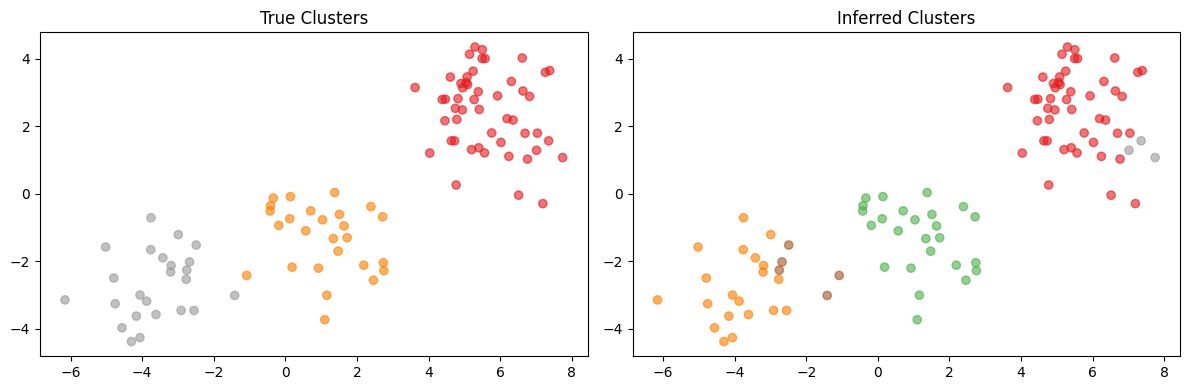

In [7]:
def cavi_update(key, y, mvniw_prior, num_iters=100, alpha=1.0, K_max=100):
    """Run variational inference updates for DPs"""
    N, D = y.shape
    K = K_max + 1

    beta0 = dist.Beta(alpha, 1.0)
    elbos = []
    u = jr.uniform(key, shape=(N, K))
    ln_qz = jnp.log(u / u.sum(-1, keepdims=True))
    for iter in range(num_iters):
        probs = jnp.exp(ln_qz)
        suma = probs.sum(0)
        args = jnp.argsort(suma)
        probs = probs[:, args[::-1]]
        if suma[-2:].sum() < 5 and iter > num_iters - K:
            probs = probs[..., :-1]

        qz = dist.Categorical(probs=probs)
        qx_z = dist.MultivariateNormal(
            loc=jnp.expand_dims(y, -2), scale_tril=jnp.eye(D) * 1e-12
        )
        mvniw_post = update_mvniw(qx_z, qz, mvniw_prior)
        dp_params = update_dp_params(qz.probs, alpha=alpha)

        log_likes = log_likelihood(y, mvniw_post)
        # Compute KL divergence for class params
        kl_div = kl_divergence(mvniw_post, mvniw_prior)
        log_likes -= kl_div

        ln_qz = update_qz(log_likes, dp_params)
        log_norm = logsumexp(ln_qz, -1, keepdims=True)
        ln_qz -= log_norm
        beta = dist.Beta(dp_params[1], dp_params[0])
        elbos.append(log_norm.sum() - kl_divergence(beta, beta0).sum())

    return qz, mvniw_post, dp_params, elbos


# Initialize variational parameters
mvniw_prior = MVNIW(
    loc=jnp.zeros(D), kappa=1 / 100, wish=dist.WishartCholesky(D + 2, jnp.eye(D))
)

K_max = 9
key, _key = jr.split(key)
qz, mvniw_post, dp_params, elbos = cavi_update(
    _key, y, mvniw_prior, num_iters=64, alpha=1, K_max=K_max
)

# Plot results
plt.figure(figsize=(12, 4))

plt.subplot(121)
plt.scatter(y[:, 0], y[:, 1], c=true_z, cmap="Set1", alpha=0.6)
plt.title("True Clusters")

plt.subplot(122)
plt.scatter(y[:, 0], y[:, 1], c=qz.probs.argmax(-1), cmap="Set1", alpha=0.6)
plt.title("Inferred Clusters")

plt.tight_layout()

In [13]:
blocks = 48
trials = 32
num_arms = 3
num_agents = 100
key = jr.PRNGKey(3447811)


def make_task(key, num_agents):
    # create task environment
    key, _key = jr.split(key)
    probs = jr.dirichlet(
        _key,
        jnp.ones(num_arms),
        shape=(
            blocks,
            1,
            1,
        ),
    )
    key, _key = jr.split(key)
    outcomes = jr.binomial(key, 1, probs, shape=(blocks, trials, num_agents, num_arms))

    return MABTask(outcomes, backend="jax")


# create an agent to read out the number of parameters
ucb_agent = UCBAgent(
    runs=num_agents, blocks=blocks, trials=trials, num_arms=num_arms, backend="jax"
)

num_params = ucb_agent.num_params

# define a transform for mapping unconstrained parameters 'z' to the corresponding agent class
transform_ucb = lambda z, **kwargs: transform(z, UCBAgent, **kwargs)

# set kwargs for transform which are passed to the agent constractor
opts_transform = {
    "blocks": blocks,
    "trials": trials,
    "num_arms": num_arms,
    "backend": "jax",
}


def make_model_and_sample(key, hyperparams, num_agents, return_model=False):
    key, _key = jr.split(key)
    mab_task = make_task(_key, num_agents)

    # set task and agent option dictionaries
    key, _key = jr.split(key)
    opts_task = {
        "task": mab_task,
        "num_blocks": blocks,
        "num_trials": trials,
        "num_agents": num_agents,
        "seed": _key[0],
    }

    # set options for prior, transform and likelihood
    opts_model = {"prior": {}, "transform": opts_transform, "likelihood": opts_task}

    prior = Prior(num_params, num_agents, hyperparams, backend="numpyro")
    gen_model = Model(prior, transform_ucb, likelihood, opts=opts_model)
    pred = Predictive(gen_model, num_samples=1)
    prior_predictive_sample = pred(key)

    ucb_agent.set_parameters(prior_predictive_sample["z"][0])
    true_vals = (ucb_agent.lr, ucb_agent.c, ucb_agent.beta)

    if return_model:
        return gen_model
    else:
        return prior_predictive_sample, true_vals


key, _key = jr.split(key)
P = dist.Wishart(
    num_params + 2,
    scale_tril=jnp.broadcast_to(
        jnp.eye(num_params) * 40 / (num_params + 2), (4, num_params, num_params)
    ),
).sample(_key)

L = jnp.linalg.cholesky(jnp.linalg.inv(P))
key, _key = jr.split(key)

v0 = jnp.array([-1.0, -0.5, 0, 0.5])
vals = []
for _ in range(num_params):
    key, _key = jr.split(key)
    vals.append(jr.permutation(_key, v0))
loc = jnp.stack(vals, -1)

loc -= jnp.array([0.0, -1.0, -1.0])

true_hyperparams = {"loc": loc, "scale_tril": L}

keys = jr.split(key, 4)
prior_predictive_sample, true_vals = vmap(make_model_and_sample, in_axes=(0, 0, None))(
    keys, true_hyperparams, num_agents // 4
)

lr 0.25460967 c 2.6297326 beta 3.4169903
lr 0.36182946 c 3.0923824 beta 2.9752398
lr 0.61486197 c 1.9712578 beta 1.9308265
lr 0.49845982 c 3.2935596 beta 2.2581542


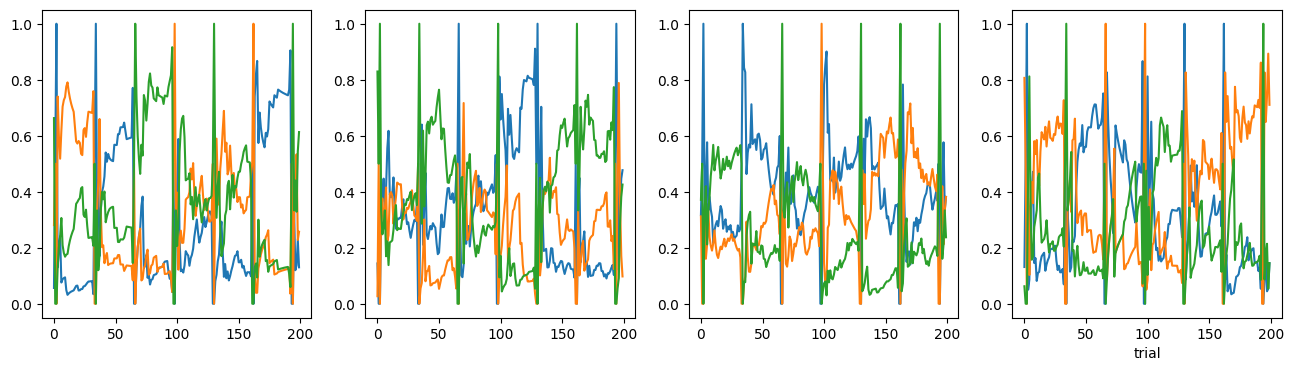

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
s = 0
for i in range(4):
    print("lr", true_vals[0][i, s], "c", true_vals[1][i, s], "beta", true_vals[2][i, s])
    logits = prior_predictive_sample["logits"][i, 0][1:, :, s, :].reshape(-1, num_arms)
    axes[i].plot(nn.softmax(logits, -1)[:200])

plt.xlabel("trial");

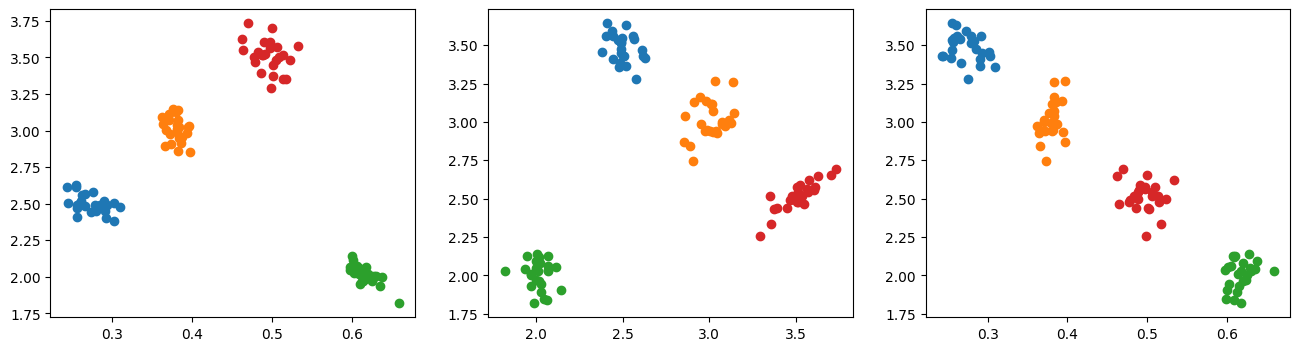

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i in range(4):
    axes[0].scatter(true_vals[0][i], true_vals[1][i])
    axes[1].scatter(true_vals[1][i], true_vals[2][i])
    axes[2].scatter(true_vals[0][i], true_vals[2][i])

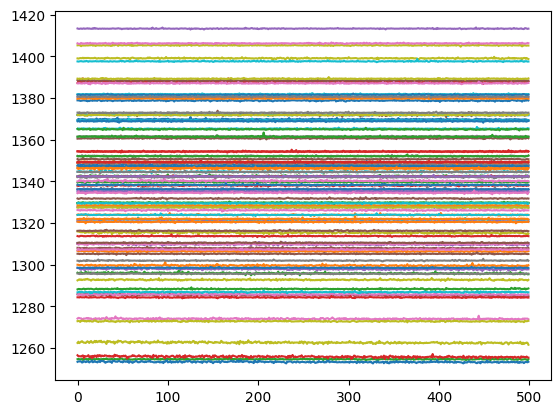

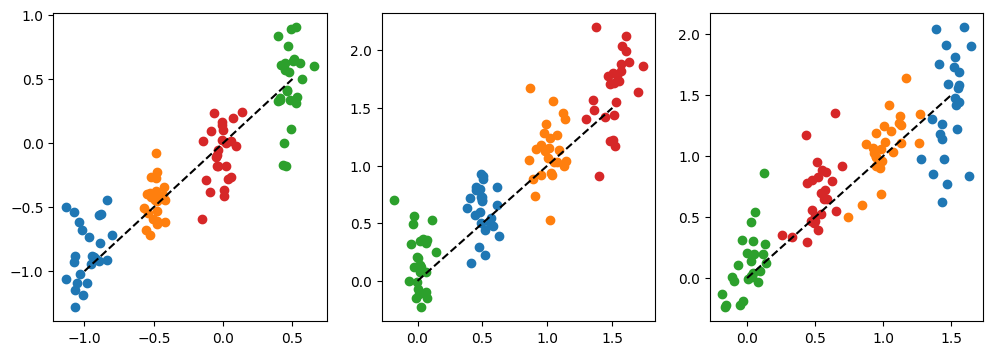

In [16]:
def log_likelihood(key, data, hyperparams):
    measurments = {
        "offers": None,
        "outcomes": data["outcomes"],
        "mask": None,
        "responses": data["responses"],
    }

    # perform inference using stochastic variational inference
    opts_svi = default_dict_svi
    opts_svi.update(
        {
            "seed": key[0],
            "iter_steps": 2500,
            "optim_kwargs": {"learning_rate": 0.001},
            "svi_kwargs": {"progress_bar": False, "stable_update": True},
        }
    )

    gen_model = make_model_and_sample(key, hyperparams, 1, return_model=True)
    posterior = Guide(Posterior(num_params, 1, backend="numpyro"))

    samples, svi, results = run_svi(gen_model, posterior, measurments, opts=opts_svi)

    return results


data = {
    "outcomes": jnp.moveaxis(prior_predictive_sample["outcomes"], 0, -2).reshape(
        blocks, trials, 1, -1
    ),
    "responses": np.moveaxis(prior_predictive_sample["responses"], 0, -2).reshape(
        blocks, trials, 1, -1
    ),
}


def get_marginal_ll(key, hyperparams, data):
    keys = jr.split(key, num_agents)
    results = vmap(log_likelihood, in_axes=(0, -1, None))(keys, data, hyperparams)
    return results


hyperparams = {
    "loc": jnp.array([0.0, 2.0, 3.0]),
    "precision_matrix": jnp.eye(num_params) / 4,
}
key, _key = jr.split(key)
results = get_marginal_ll(_key, hyperparams, data)

plt.plot(results.losses.mT[-500:])

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

locs = results.params["loc"].reshape(4, 25, num_params)

for i in range(3):
    for j in range(4):
        axes[i].scatter(prior_predictive_sample["z"][j, 0, :, i], locs[j, :, i])
    vals = [loc[:, i].min(), loc[:, i].max()]
    axes[i].plot(vals, vals, "k--")

In [ ]:
alpha = 1
N = 100
K = 10
beta0 = dist.Beta(alpha, 1.0)

dp_params = (jnp.ones(K - 1), jnp.ones(K - 1) * alpha)

mvniw_prior = MVNIW(
    loc=jnp.zeros(num_params),
    kappa=1 / 10,
    wish=dist.WishartCholesky(
        num_params + 2, jnp.eye(num_params) * 10 / (num_params + 2)
    ),
)

key, _key = jr.split(key)
mvniw_post = MVNIW(
    loc=jr.normal(_key, shape=(K, num_params)) / jnp.sqrt(10 * mvniw_prior.kappa),
    kappa=1 / 10,
    wish=dist.WishartCholesky(
        num_params + 2, jnp.eye(num_params) * 10 / (num_params + 2)
    ),
)

elbos = []
for _ in range(8):
    nu = mvniw_post.wish.concentration
    P = jnp.broadcast_to(
        nu[..., None, None] * mvniw_post.wish.scale_matrix,
        (K, num_params, num_params),
    )
    hyperparams = {
        "loc": mvniw_post.loc,
        "precision_matrix": P,
    }

    # estimate posterior parameters with numpyro
    key, _key = jr.split(key)
    keys = jr.split(_key, K)
    results = vmap(get_marginal_ll, in_axes=(0, 0, None))(keys, hyperparams, data)

    log_likes = -results.losses[..., -20:].mean(-1).mT

    kl_div = kl_divergence(mvniw_post, mvniw_prior)
    log_likes -= kl_div

    residual = 0.5 * (
        multivariate_digamma(nu / 2, num_params)
        + num_params * jnp.log(2)
        - num_params / mvniw_post.kappa
        - jnp.log(nu)
    )
    log_likes += residual

    ln_qz = update_qz(log_likes, dp_params)
    log_norm = logsumexp(ln_qz, -1, keepdims=True)
    probs = jnp.exp(ln_qz - log_norm)
    suma = probs.sum(0)
    srt_idx = jnp.argsort(suma, -1)[::-1]
    qz = dist.Categorical(probs=probs[:, srt_idx])

    _loc = jnp.moveaxis(results.params["loc"].squeeze(-2), 0, 1)
    _sl = jnp.moveaxis(results.params["scale_tril"].squeeze(-3), 0, 1)
    qx_z = dist.MultivariateNormal(
        loc=_loc[:, srt_idx],
        scale_tril=_sl[:, srt_idx],
    )

    mvniw_post = update_mvniw(qx_z, qz, mvniw_prior)
    dp_params = update_dp_params(qz.probs, alpha=alpha)

    beta = dist.Beta(dp_params[1], dp_params[0])
    elbos.append(log_norm.sum() - kl_divergence(beta, beta0).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(elbos)
sns.heatmap(qz.probs, ax=axes[1])

In the second variant we only fit the model once, and then just use BMR to refine the posterior and learn DP. 

In [17]:
from jax.scipy.linalg import solve


def ΔF_mv(mu, P, mu1, P1, P0):
    # Delta F for multivariate normal prior-posterior
    t_P = P + P1 - P0

    _, logdet = jnp.linalg.slogdet(t_P)
    df = -logdet / 2

    _, logdet = jnp.linalg.slogdet(P1)
    df += logdet / 2

    _, logdet = jnp.linalg.slogdet(P)
    df += logdet / 2

    df -= jnp.linalg.slogdet(P0)[1]

    _mu = P @ mu
    _mu1 = P1 @ mu1
    t_mu = solve(t_P, _mu, assume_a="pos")

    df -= jnp.inner(_mu, mu) / 2
    df -= jnp.inner(_mu1, mu1) / 2
    df += jnp.inner(_mu + _mu1, t_mu) / 2

    return df, t_mu, t_P


def del_f(mu, P, mu1, P1, P0):
    return vmap(ΔF_mv, in_axes=(None, None, 0, 0, None))(mu, P, mu1, P1, P0)

In [26]:
scale = 2
hyperparams0 = {"loc": jnp.zeros(num_params), "scale_tril": jnp.eye(num_params) * scale}
key, _key = jr.split(key)
results0 = get_marginal_ll(_key, hyperparams0, data)

In [38]:
K = N
alpha = 1
probs = jnp.eye(N)
beta0 = dist.Beta(alpha, 1.0)
qz = dist.Categorical(probs=probs)

mvniw_prior = MVNIW(
    loc=jnp.zeros(num_params),
    kappa=1 / 10,
    wish=dist.WishartCholesky(
        num_params + 2, jnp.eye(num_params) * 10 / (num_params + 2)
    ),
)

qx_z = dist.MultivariateNormal(
    loc=results0.params["loc"],
    scale_tril=results0.params["scale_tril"],
)

mvniw_post = update_mvniw(qx_z, qz, mvniw_prior)
dp_params = update_dp_params(qz.probs, alpha=alpha)

<Axes: >

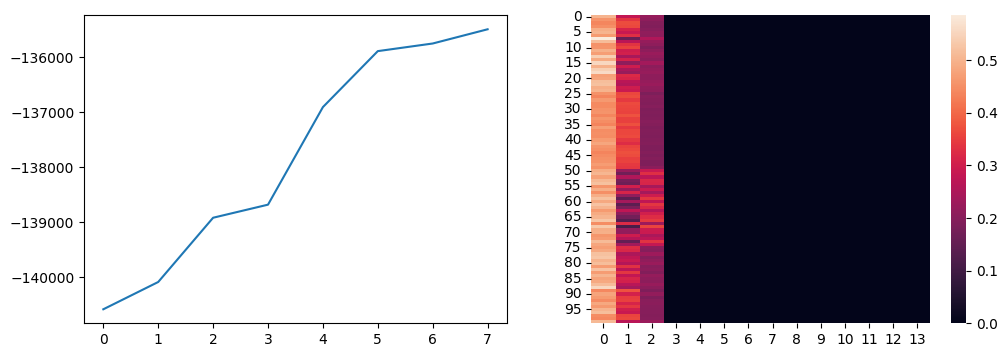

In [39]:
mu = results0.params["loc"].squeeze(-2)
L = results0.params["scale_tril"].squeeze(-3)
P = jnp.linalg.inv(L @ L.mT)
P0 = jnp.eye(num_params) / jnp.square(scale)
ll0 = -results0.losses[:, -100:].mean(-1, keepdims=True)
cutoff = 1e-8
elbos = []
for _ in range(8):
    mu1 = mvniw_post.loc
    nu = mvniw_post.wish.concentration
    P1 = nu[..., None, None] * mvniw_post.wish.scale_matrix
    # P1 = jnp.broadcast_to(P0 * nu[..., None, None], P1.shape)

    df, t_mu, t_P = vmap(del_f, in_axes=(0, 0, None, None, None))(mu, P, mu1, P1, P0)

    ll = ll0 + df

    kl_div = kl_divergence(mvniw_post, mvniw_prior)
    ll -= kl_div

    residual = 0.5 * (
        multivariate_digamma(nu / 2, num_params)
        + num_params * jnp.log(2)
        - num_params / mvniw_post.kappa
        - jnp.log(nu)
    )
    ll += residual

    ln_qz = update_qz(ll, dp_params)
    log_norm = logsumexp(ln_qz, -1, keepdims=True)
    probs = jnp.exp(ln_qz - log_norm)
    suma = probs.sum(0)
    srt_idx = jnp.argsort(suma, -1)[::-1]
    suma = suma[srt_idx]
    qz = dist.Categorical(probs=probs[:, srt_idx][:, suma > cutoff])

    _loc = t_mu[:, srt_idx][:, suma > cutoff]
    _pi = t_P[:, srt_idx][:, suma > cutoff]
    qx_z = dist.MultivariateNormal(
        loc=_loc,
        precision_matrix=_pi,
    )

    mvniw_post = update_mvniw(qx_z, qz, mvniw_prior)
    dp_params = update_dp_params(qz.probs, alpha=alpha)

    beta = dist.Beta(dp_params[1], dp_params[0])
    elbos.append(log_norm.sum() - kl_divergence(beta, beta0).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(elbos)
sns.heatmap(qz.probs, ax=axes[1])

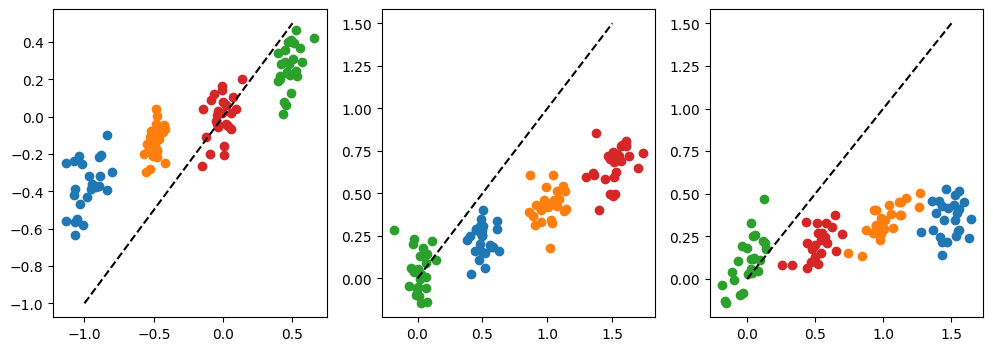

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

locs = jnp.sum(qx_z.mean * qz.probs[..., None], -2).reshape(4, 25, -1)
for i in range(3):
    for j in range(4):
        axes[i].scatter(prior_predictive_sample["z"][j, 0, :, i], locs[j, :, i])
    vals = [loc[:, i].min(), loc[:, i].max()]
    axes[i].plot(vals, vals, "k--")

<Axes: >

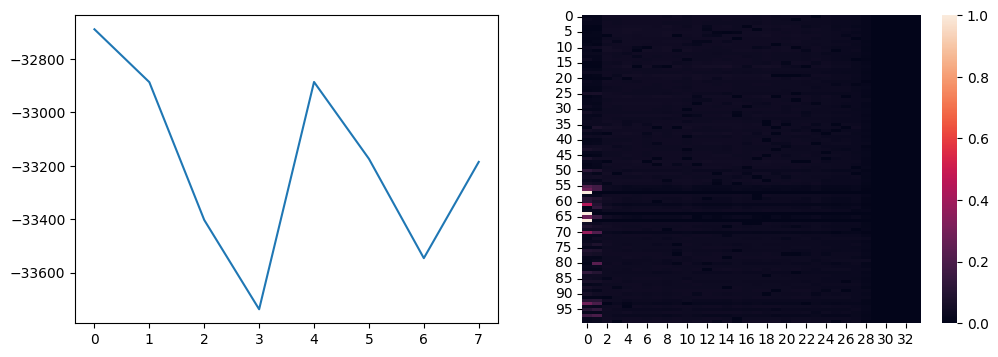

In [ ]:
elbos = []
K = qz.probs.shape[-1]
for _ in range(8):
    nu = mvniw_post.wish.concentration
    P = nu[..., None, None] * mvniw_post.wish.scale_matrix
    hyperparams = {
        "loc": mvniw_post.loc,
        "precision_matrix": P,
    }

    # estimate posterior parameters with numpyro
    key, _key = jr.split(key)
    keys = jr.split(_key, K)
    results = vmap(get_marginal_ll, in_axes=(0, 0, None))(keys, hyperparams, data)

    log_likes = -results.losses[..., -20:].mean(-1).mT

    kl_div = kl_divergence(mvniw_post, mvniw_prior)
    log_likes -= kl_div

    residual = 0.5 * (
        multivariate_digamma(nu / 2, num_params)
        + num_params * jnp.log(2)
        - num_params / mvniw_post.kappa
        - jnp.log(nu)
    )
    log_likes += residual

    ln_qz = update_qz(log_likes, dp_params)
    log_norm = logsumexp(ln_qz, -1, keepdims=True)
    probs = jnp.exp(ln_qz - log_norm)
    suma = probs.sum(0)
    srt_idx = jnp.argsort(suma, -1)[::-1]
    qz = dist.Categorical(probs=probs[:, srt_idx])

    _loc = jnp.moveaxis(results.params["loc"].squeeze(-2), 0, 1)
    _sl = jnp.moveaxis(results.params["scale_tril"].squeeze(-3), 0, 1)
    qx_z = dist.MultivariateNormal(
        loc=_loc[:, srt_idx],
        scale_tril=_sl[:, srt_idx],
    )

    mvniw_post = update_mvniw(qx_z, qz, mvniw_prior)
    dp_params = update_dp_params(qz.probs, alpha=alpha)

    beta = dist.Beta(dp_params[1], dp_params[0])
    elbos.append(log_norm.sum() - kl_divergence(beta, beta0).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(elbos)
sns.heatmap(qz.probs, ax=axes[1])